Original training data shape: (60000, 28, 28, 1)
Original test data shape: (10000, 28, 28, 1)
Noisy training data shape: (60000, 28, 28, 1)
Noisy test data shape: (10000, 28, 28, 1)


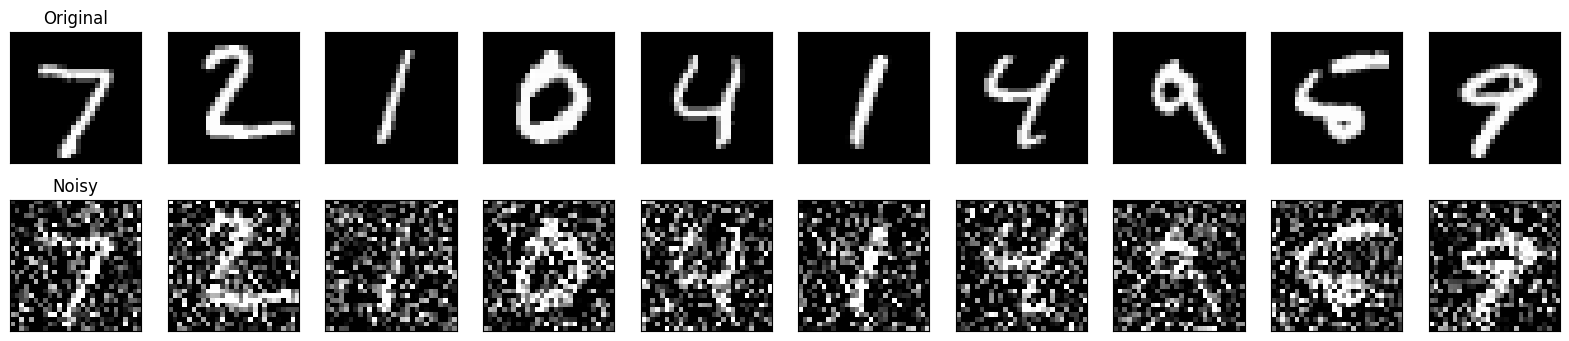

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,353 (110.75 KB)

 Trainable params: 28,353 (110.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 119s 251ms/step - loss: 0.1654 - val_loss: 0.1165
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 118s 252ms/step - loss: 0.1126 - val_loss: 0.1081
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 123s 262ms/step - loss: 0.1073 - val_loss: 0.1047
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 122s 260ms/step - loss: 0.1046 - val_loss: 0.1026
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 138s 252ms/step - loss: 0.1027 - val_loss: 0.1012
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 140s 248ms/step - loss: 0.1015 - val_loss: 0.1000
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 116s 248ms/step - loss: 0.1005 - val_loss: 0.0995
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 115s 245ms/step - loss: 0.0997 - val_loss: 0.0988
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 115s 246ms/step - loss: 0.0991 - val_loss: 0.0985
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 145s 253ms/step - loss: 0.0985 - val_loss: 0.0975


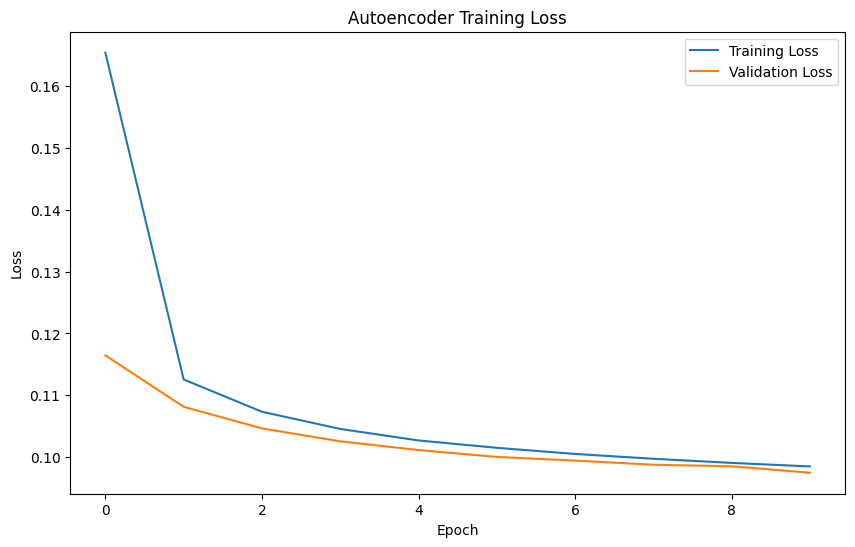

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step


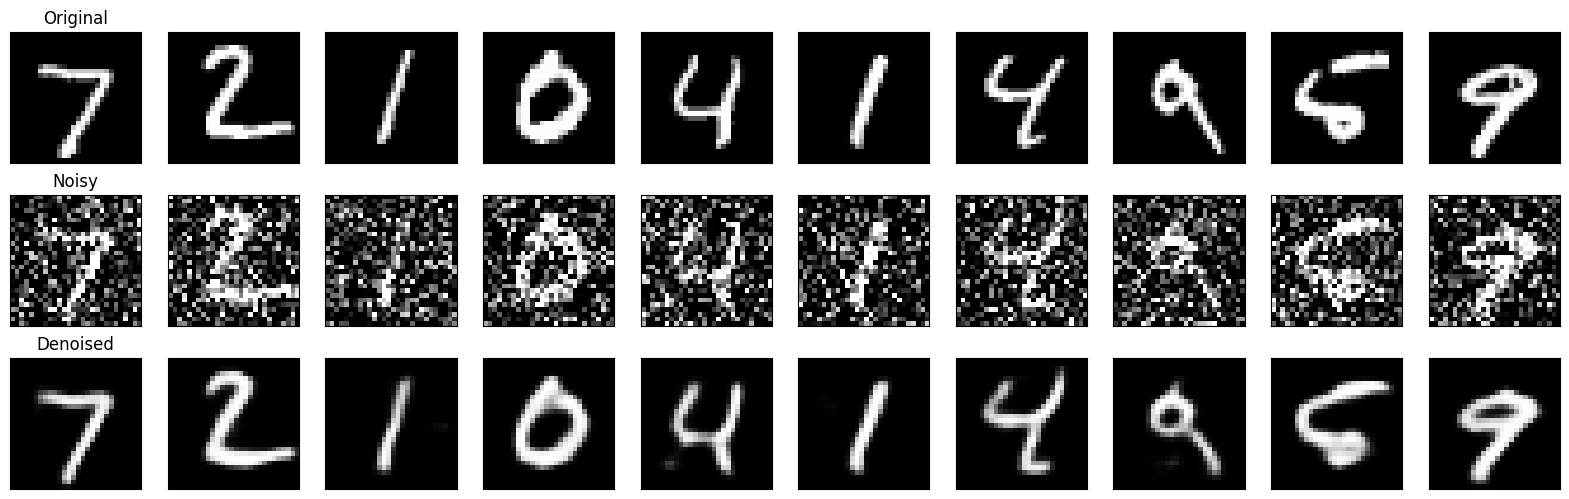

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    UpSampling2D
)

# Load the MNIST dataset
(x_train, _), (x_test, _) = mnist.load_data()

# Normalize pixel values between 0 and 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Reshape images to include the channel dimension
x_train = np.reshape(x_train, (len(x_train), 28, 28, 1))
x_test = np.reshape(x_test, (len(x_test), 28, 28, 1))

print("Original training data shape:", x_train.shape)
print("Original test data shape:", x_test.shape)

# Add random noise to the images
noise_factor = 0.5

x_train_noisy = x_train + noise_factor * np.random.normal(
    loc=0.0, scale=1.0, size=x_train.shape
)

x_test_noisy = x_test + noise_factor * np.random.normal(
    loc=0.0, scale=1.0, size=x_test.shape
)

# Keep pixel values between 0 and 1
x_train_noisy = np.clip(x_train_noisy, 0., 1.)
x_test_noisy = np.clip(x_test_noisy, 0., 1.)

print("Noisy training data shape:", x_train_noisy.shape)
print("Noisy test data shape:", x_test_noisy.shape)

# Display original and noisy images
n = 10

plt.figure(figsize=(20, 4))

for i in range(n):
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    if i == 0:
        ax.set_title("Original")

    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(x_test_noisy[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    if i == 0:
        ax.set_title("Noisy")

plt.show()

# Build the convolutional autoencoder
input_img = Input(shape=(28, 28, 1))

# Encoder
x = Conv2D(
    32, (3, 3), activation='relu', padding='same'
)(input_img)

x = MaxPooling2D(
    (2, 2), padding='same'
)(x)

x = Conv2D(
    32, (3, 3), activation='relu', padding='same'
)(x)

encoded = MaxPooling2D(
    (2, 2), padding='same'
)(x)

# Decoder
x = Conv2D(
    32, (3, 3), activation='relu', padding='same'
)(encoded)

x = UpSampling2D((2, 2))(x)

x = Conv2D(
    32, (3, 3), activation='relu', padding='same'
)(x)

x = UpSampling2D((2, 2))(x)

decoded = Conv2D(
    1, (3, 3), activation='sigmoid', padding='same'
)(x)

# Create and compile the autoencoder
autoencoder = Model(input_img, decoded)

autoencoder.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

# Display model architecture
autoencoder.summary()

# Train the autoencoder
epochs = 10
batch_size = 128

history = autoencoder.fit(
    x_train_noisy,
    x_train,
    epochs=epochs,
    batch_size=batch_size,
    shuffle=True,
    validation_data=(x_test_noisy, x_test)
)

# Plot training and validation loss
plt.figure(figsize=(10, 6))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Autoencoder Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Generate denoised images
denoised_images = autoencoder.predict(x_test_noisy)

# Display original, noisy, and denoised images
n = 10

plt.figure(figsize=(20, 6))

for i in range(n):

    # Original image
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    if i == 0:
        ax.set_title('Original')

    # Noisy image
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_test_noisy[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    if i == 0:
        ax.set_title('Noisy')

    # Denoised image
    ax = plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(denoised_images[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    if i == 0:
        ax.set_title('Denoised')

plt.show()

